# 02 · Replicating Fournié et al. (1999), Section 4

The paper used low-discrepancy sequences; we show scrambled Sobol and pseudorandom runs. Regenerate with `python scripts/reproduce_paper.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from mc_greeks import *
from mc_greeks.estimators import exact_estimator_moments, per_path_function
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "results" / "tables"
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

In [2]:
t = pd.read_csv(TABLES / 'A_paper_table.csv')
t[t.sampler.str.startswith('Sobol')][['payoff','greek','method','h','exact','paper_exact','paper_fd','paper_malliavin','first_run','rmse']]

,payoff,greek,method,h,exact,paper_exact,paper_fd,paper_malliavin,first_run,rmse
0,interval,delta,Malliavin,NaN,-0.00133486,-0.001335,-0.003167,-0.001335,-0.00133453,1.56936e-06
2,interval,delta,FD-CRN-ctr,1,-0.00133486,-0.001335,-0.003167,-0.001335,-0.00135726,6.44805e-05
4,interval,delta,FD-CRN-ctr,0.1,-0.00133486,-0.001335,-0.003167,-0.001335,-0.000904837,0.000652592
6,interval,gamma,Malliavin,NaN,-0.000388757,-0.000389,0.099532,-0.000389,-0.000388693,2.37499e-07
8,interval,gamma,FD-CRN-ctr,1,-0.000388757,-0.000389,0.099532,-0.000389,-0.000361935,0.000264502
10,interval,gamma,FD-CRN-ctr,0.1,-0.000388757,-0.000389,0.099532,-0.000389,0.0361935,0.022768
12,interval,vega,Malliavin,NaN,-0.777514,-0.777516,-0.542902,-0.778695,-0.777386,0.000474999
14,interval,vega,FD-CRN-ctr,0.01,-0.777514,-0.777516,-0.542902,-0.778695,-0.796257,0.00643985
16,interval,vega,FD-CRN-ctr,0.001,-0.777514,-0.777516,-0.542902,-0.778695,-0.72387,0.0474668
18,call,delta,Malliavin-loc,NaN,0.725747,0.725747,0.725639,0.72566,0.725717,2.78135e-05


Running estimates (paper Figs. 1–3):

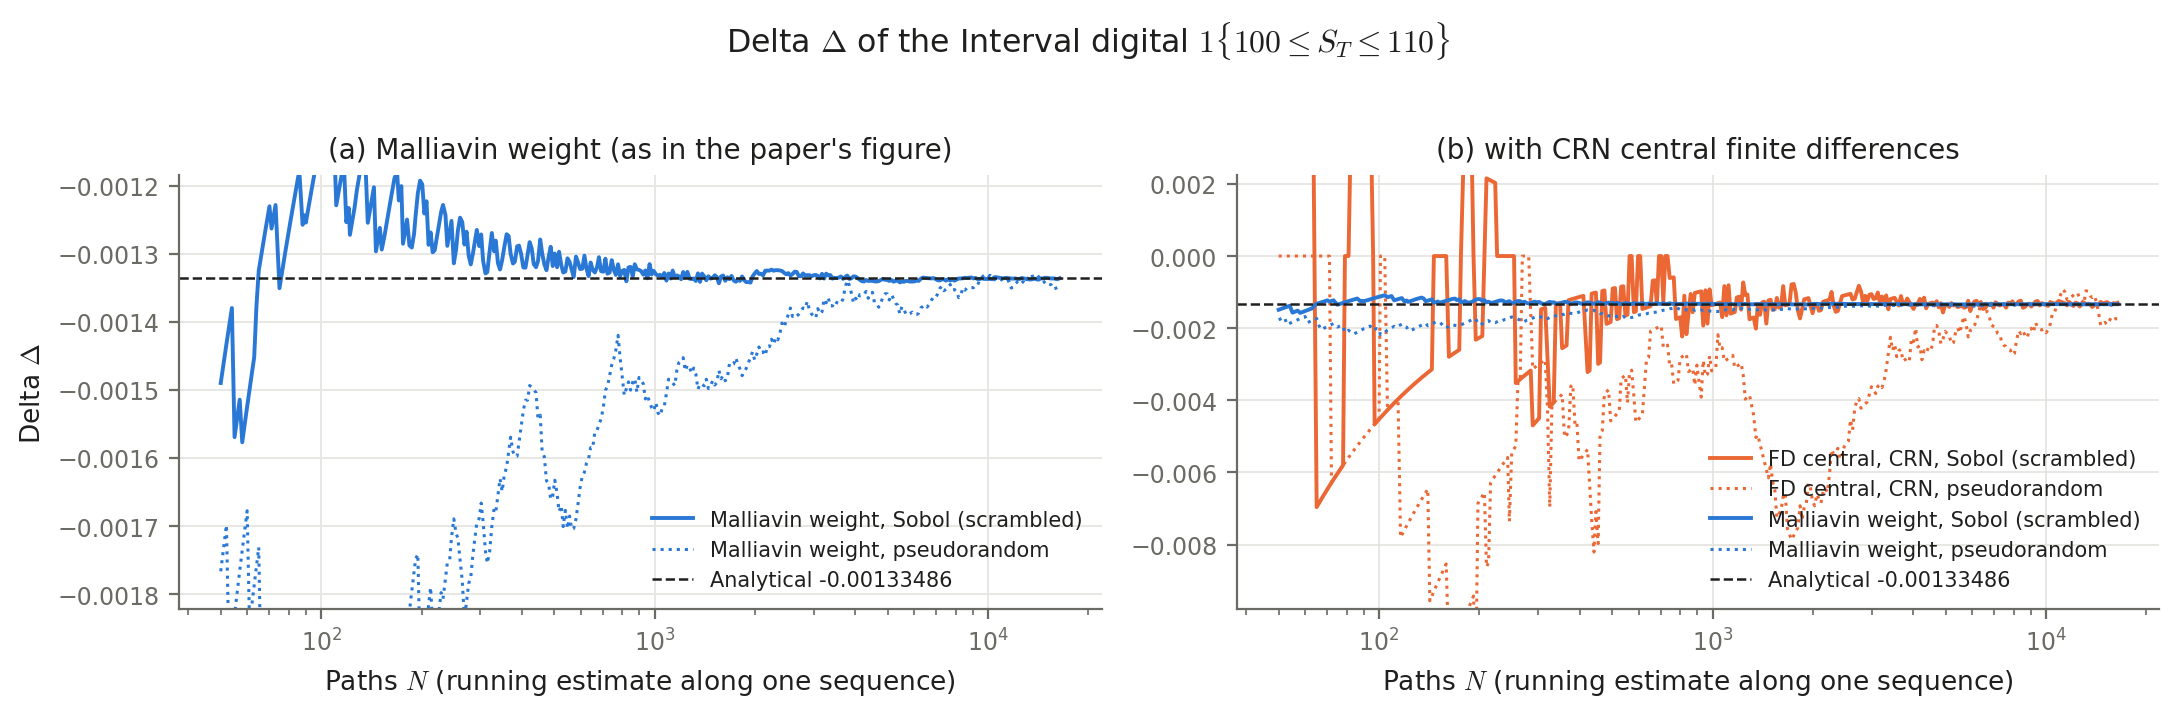

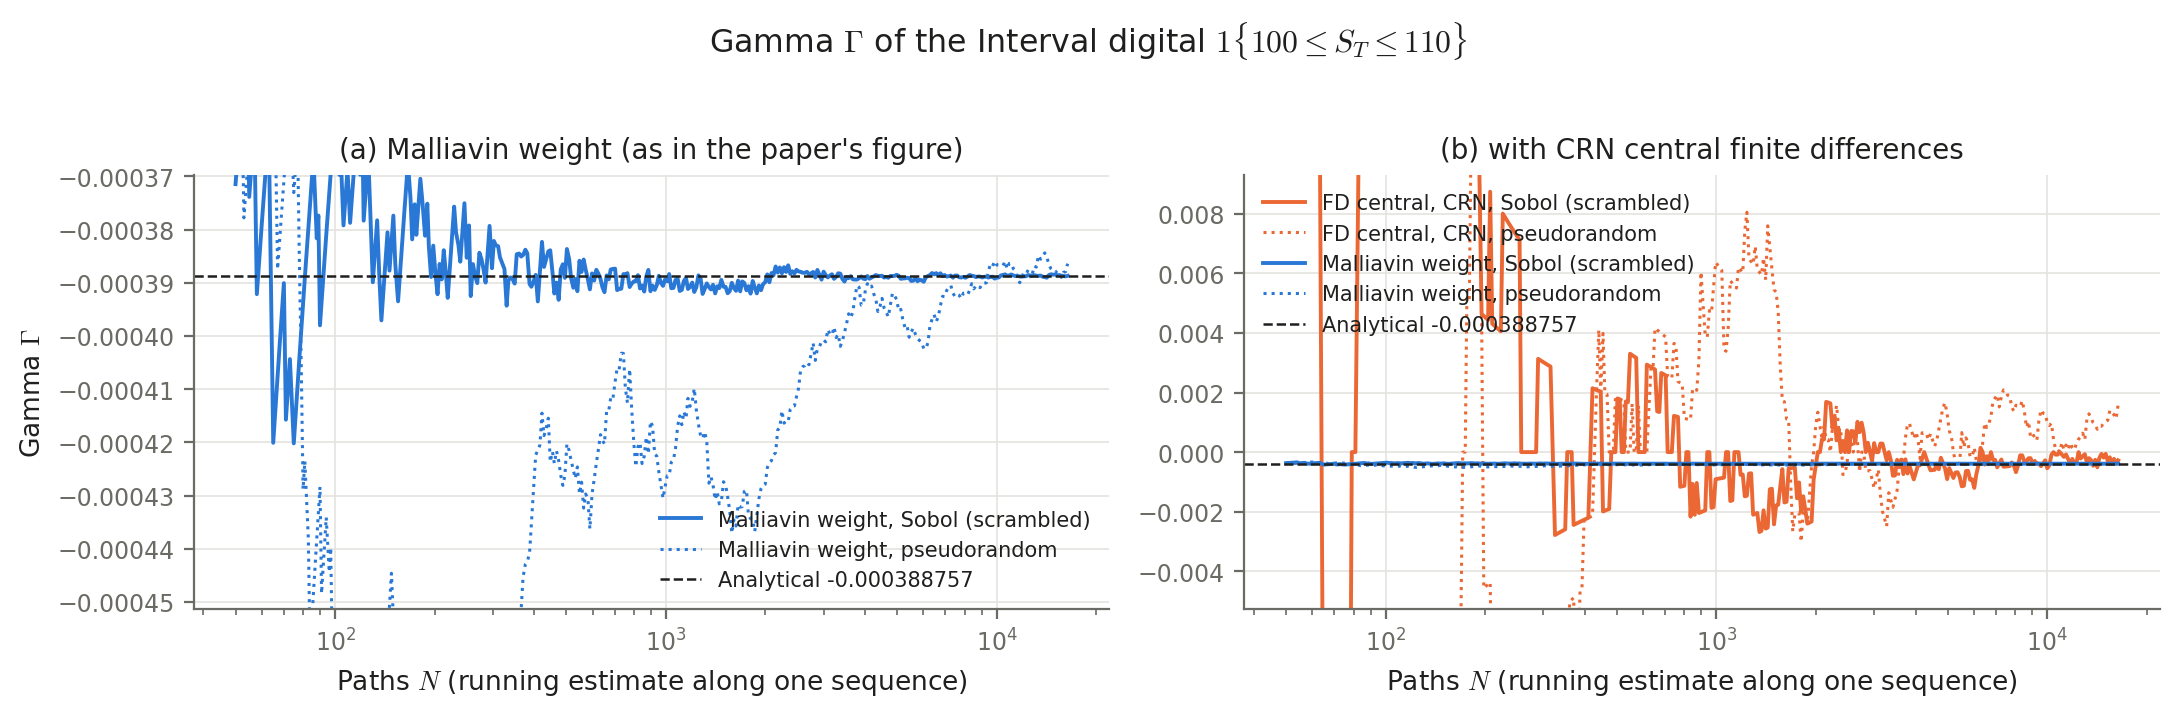

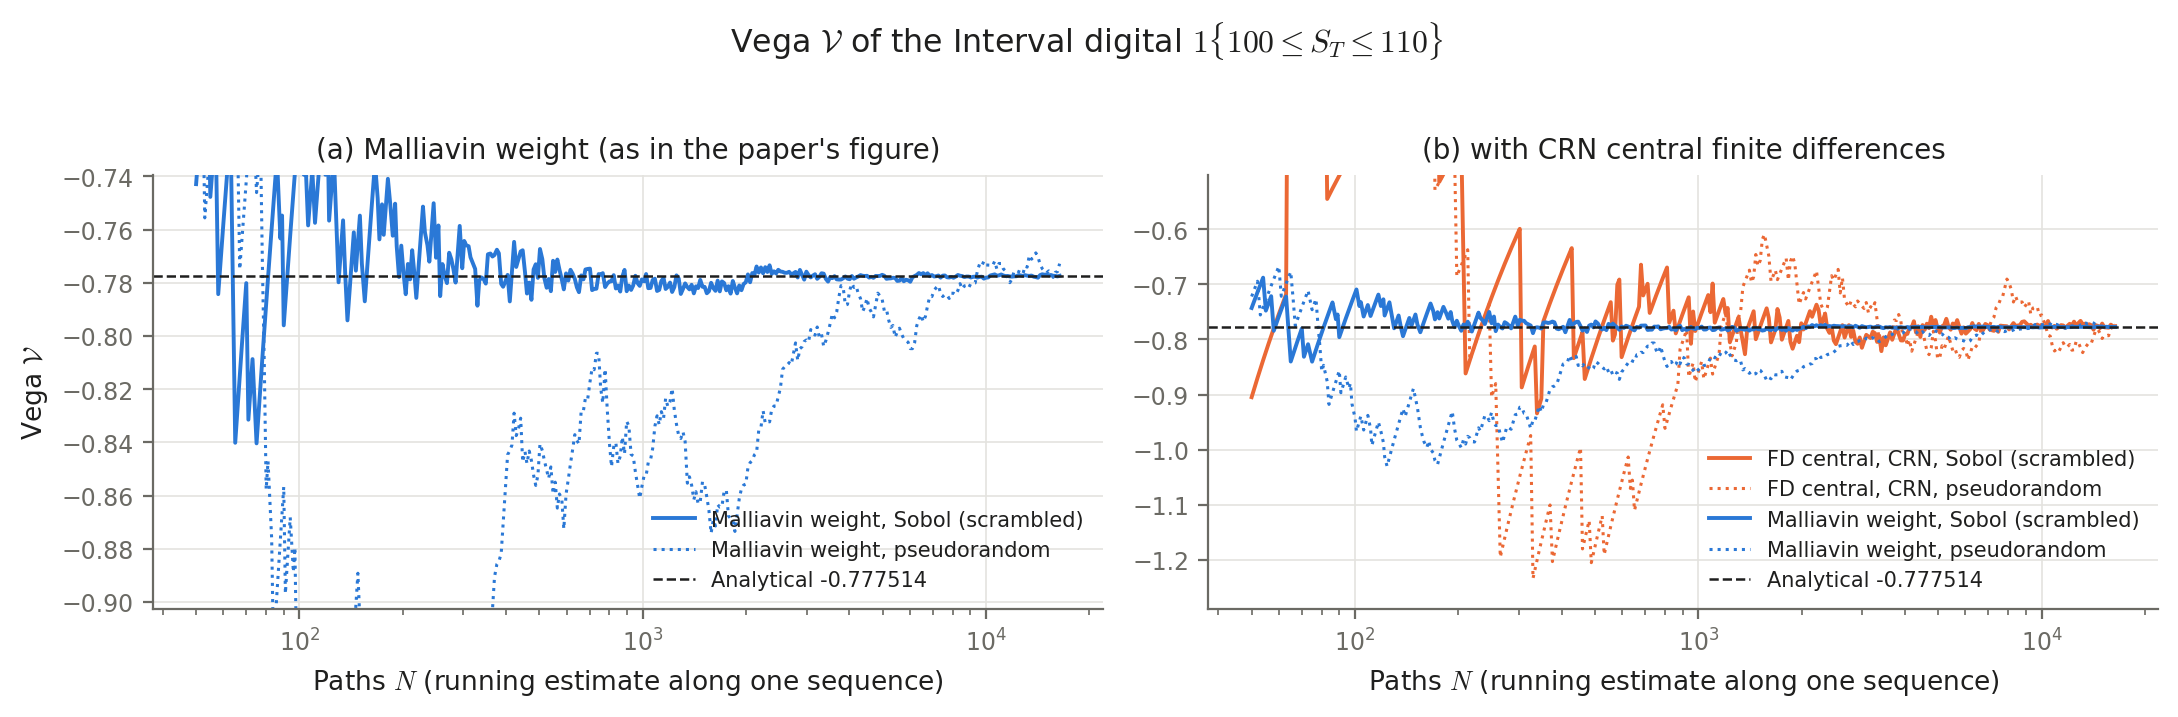

In [3]:
from IPython.display import Image, display
for g in ['delta','gamma','vega']:
    display(Image(str(ROOT / f'results/figures/figA{["delta","gamma","vega"].index(g)+1}_paper_interval_{g}_trajectory.png')))

In [4]:
pd.read_csv(TABLES / 'A_rqmc_slopes.csv')[['greek','sampler','slope','slope_lo','slope_hi']]

,greek,sampler,slope,slope_lo,slope_hi
0,delta,Sobol (scrambled),-0.986456,-1.09343,-0.879478
1,delta,pseudorandom,-0.489159,-0.52207,-0.456248
2,gamma,Sobol (scrambled),-0.999089,-1.11474,-0.883443
3,gamma,pseudorandom,-0.495488,-0.517856,-0.473119
4,vega,Sobol (scrambled),-0.999089,-1.11474,-0.883443
5,vega,pseudorandom,-0.495488,-0.517856,-0.473119
